This notebook calculates and plots the time to entanglement T_ent as a function of memory efficiency for Fig. 8 of the main text

In [1]:
using CairoMakie
using LaTeXStrings
include("Protocol_Fns.jl")

gen_probs (generic function with 1 method)

In [2]:
##### parameters set I - "optimistic" values

F_targ= 0.9 #target fidelity
_, η_FC, η_i_io = fill(0.8,3)
η_d, η_AFC0 = fill(0.9,2)
η_herald = 0.97
N_bin=10 
M=1000 #multiplexing modes
r=0.4 #dephasing parameter
epsilon_m=0.5; nu = 1; Lambda_0= nu/2; filt_params = (Lambda_0, nu, epsilon_m); #low pass filter parameters
T_EN = 10*1e-6; #effective time between ion pulse attempts

In [3]:
L = 150*1e3;
η_array = range(0.1,1,length=50)
M_M_results = Dict(); #initialize memory matching results

for (sc_label, sc_key) in [(:SC, true), (:DC, false)]
    for (repeater_label, repeater_key) in [(:repeater, 1), (:no_repeater, 0)]
        for (turn_label, turn_key) in [(:on, false), (:off, true)]
            M_M_results[(sc_label, turn_label, repeater_label)] = map(η_m -> Memory_Match(
                repeater_key, L, (η_m, η_d, η_i_io, η_FC, η_AFC0, η_herald), F_targ, M, filt_params;
                single_click = sc_key,
                r = r,
                turn_off = turn_key
            ), η_array)
        end
    end
end
#We can access the parameters,
#T_ent, T_m_w, T_i_w, N_ion, P_i, P_SPDC, F_0 = M_M_results[(:SC/:DC, :on/:off, :repeater/:no_repeater)],
#Where each of the output is a vector as a function of memory efficiency

SPDC_M_results = Dict();
# We tie the SPDC (memory) turn-off to the ion turn-off. For SC it has no effect at the order considered; for DC it enters only through I_0 and κ_0 (a small effect).
for (sc_label, sc_key) in [(:SC, true), (:DC, false)]
    for (repeater_label, repeater_key) in [(:repeater, 1), (:no_repeater, 0)]
        for (turn_label, turn_key) in [(:on, false), (:off, true)]
            SPDC_M_results[(sc_label, turn_label, repeater_label)] = map(η_m -> SPDC_Match(
                repeater_key, L, (η_m, η_d, η_i_io, η_FC, η_herald), F_targ, M, N_bin, T_EN;
                single_click = sc_key,
                r = r,
                turn_off = turn_key,
                turn_off_mem = turn_key
            ), η_array)
        end
    end
end
#We can access the parameters,
#T_ent, T_m_w, T_i_w, N_ion, P_i, P_SPDC, P_b = SPDC_M_results[(:SC/:DC, :on/:off, :repeater/:no_repeater)],
#Where each of the output is a vector as a function of memory efficiency


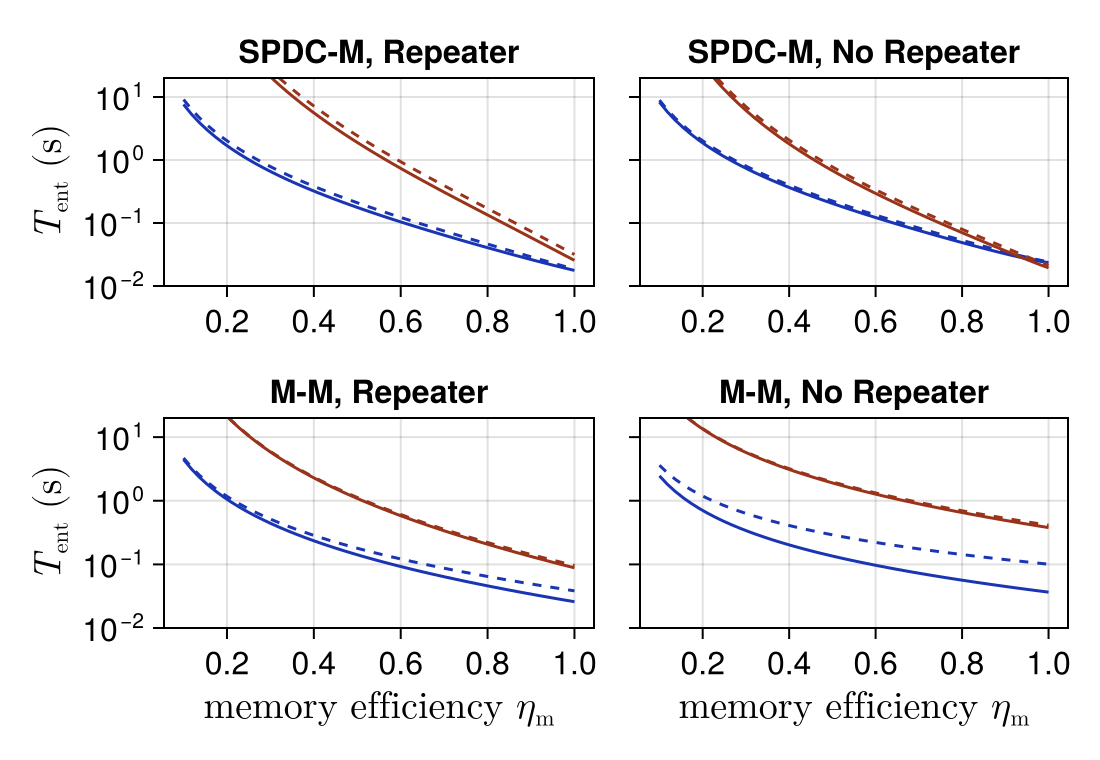

In [4]:
#Generate plot for Fig. 8(a) of main text.

fig8a = Figure(size = (550, 380))
C_red  = RGBf(0.6,0.2,0.1); C_blue = RGBf(0.1,0.21,0.7)
f_size, t_size, y_size, leg_size = 16, 16, 19, 14
ylm = (1e-2, 2e1);
colors = Dict(:SC => C_blue, :DC => C_red)
linestyles = Dict(:on => :dash, :off => :solid)
linestyle_labels = Dict(:on => "", :off  => "turn-off")
titles = [    "SPDC-M, Repeater"        "SPDC-M, No Repeater"; "M-M, Repeater"      "M-M, No Repeater"]
for (i, dataset) in enumerate((SPDC_M_results, M_M_results))
    for (j, repeater_label) in enumerate((:repeater, :no_repeater))
        ax = Axis(fig8a[i, j],ylabel = j ==  1 ?  L"T_{\mathrm{ent}} \ \mathrm{ (s)}" : "", yticklabelsvisible = (j == 1),xlabel = i == 2 ?  L"\mathrm{memory \ efficiency } \ \eta_{\mathrm{m}}" : "", yscale = log10, title = titles[i,j], xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size, xticklabelsize = f_size, yticklabelsize = f_size)
        ylims!(ax, ylm)
        for sc_label in (:SC, :DC)
            for turn_label in (:on, :off)
                T_ent = first.(dataset[(sc_label, turn_label, repeater_label)])
                lines!(ax, η_array, abs.(T_ent); color = colors[sc_label], linestyle = linestyles[turn_label], label = "$(sc_label), $(linestyle_labels[turn_label])")
            end
        end
    end
end

#save("Memory_Plot_PSetI.pdf", fig8a)
fig8a

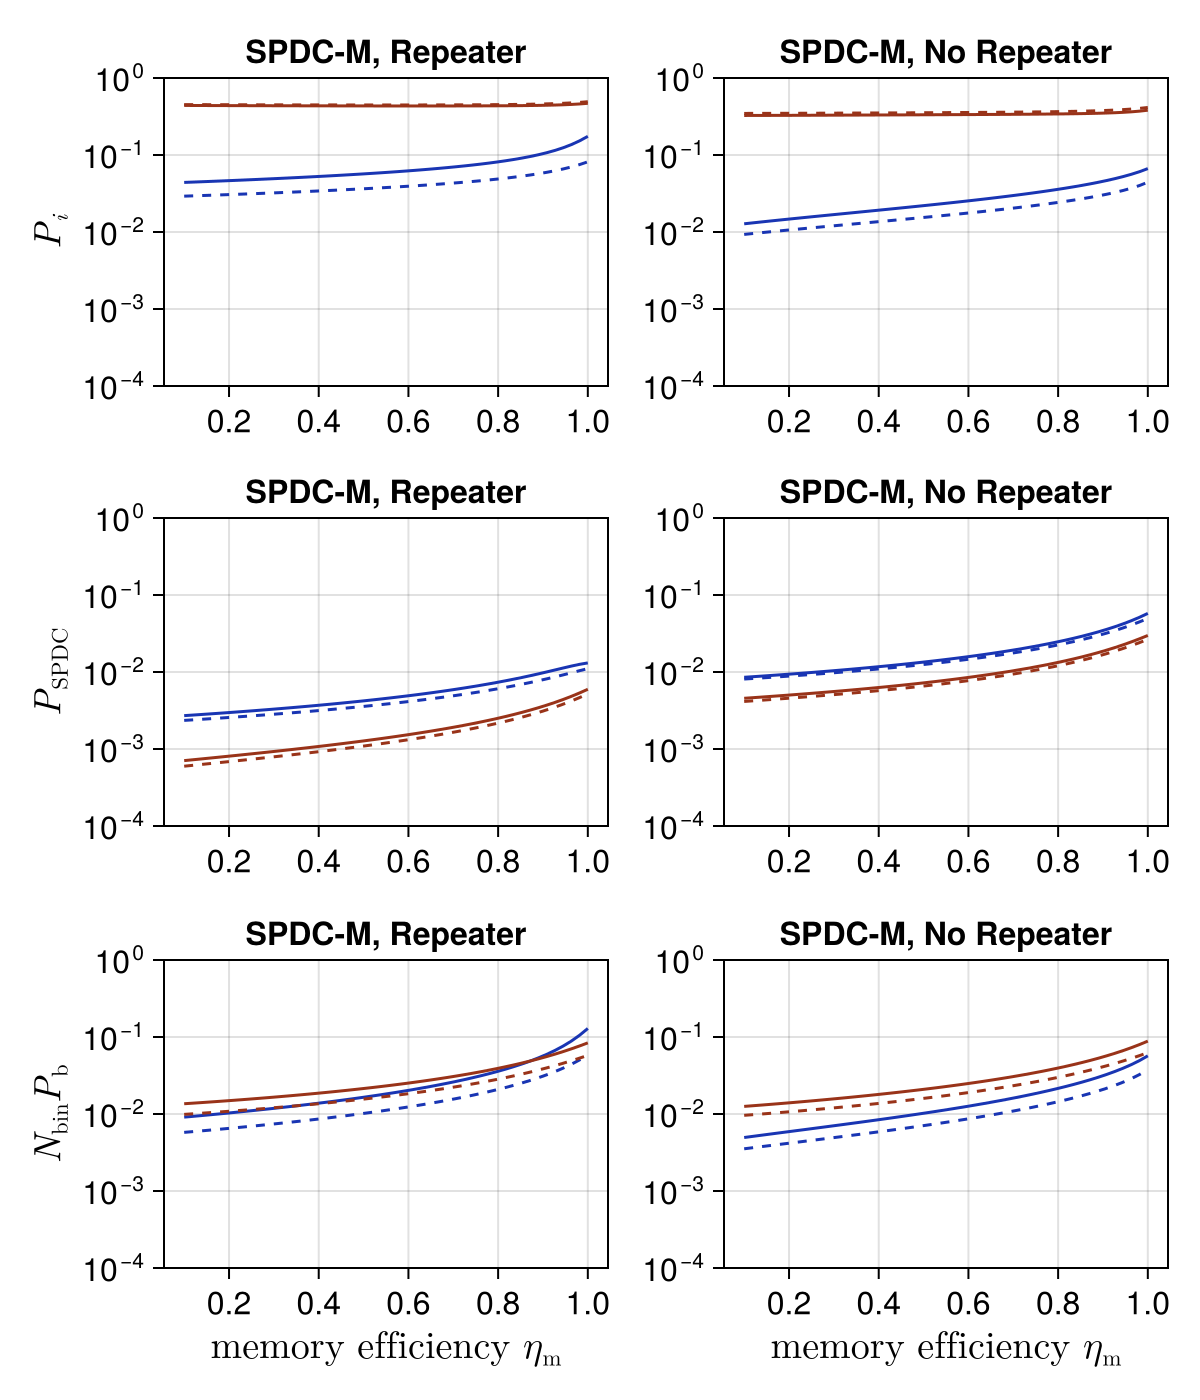

In [5]:
#Need to make plots of photon numbers for optimization, to make sure things are sensible.
figphot1 = Figure(size = (600, 700))
ylm = (1e-4,1); 
titles = [    "SPDC-M, Repeater"        "SPDC-M, No Repeater"]
for (j, repeater_label) in enumerate((:repeater, :no_repeater))
    ax = Axis(figphot1[1, j],ylabel = j ==  1 ?  L"P_i " : "", xlabel =  "", yscale = log10, title = titles[1,j], xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size, xticklabelsize = f_size, yticklabelsize = f_size)
    ylims!(ax, ylm)
    for sc_label in (:SC, :DC)
        for turn_label in (:on, :off)
            temp = getindex.(SPDC_M_results[(sc_label, turn_label, repeater_label)],5)
            lines!(ax, η_array,temp; color = colors[sc_label], linestyle = linestyles[turn_label], label = "$(sc_label), $(linestyle_labels[turn_label])")
        end
    end
    ax = Axis(figphot1[2, j],ylabel = j ==  1 ?  L"P_{\mathrm{SPDC}}" : "", xlabel = "", yscale = log10, title = titles[1,j], xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size, xticklabelsize = f_size, yticklabelsize = f_size)
    ylims!(ax, ylm)
    for sc_label in (:SC, :DC)
        for turn_label in (:on, :off)
            temp = getindex.(SPDC_M_results[(sc_label, turn_label, repeater_label)],6)
            lines!(ax, η_array, temp; color = colors[sc_label], linestyle = linestyles[turn_label], label = "$(sc_label), $(linestyle_labels[turn_label])")
        end
    end
    ax = Axis(figphot1[3, j],ylabel = j ==  1 ?  L"N_{\mathrm{bin}}P_{\mathrm{b}}" : "", xlabel =  L"\mathrm{memory \ efficiency } \ \eta_{\mathrm{m}}", yscale = log10, title = titles[1,j], xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size, xticklabelsize = f_size, yticklabelsize = f_size)
    ylims!(ax, ylm)
    for sc_label in (:SC, :DC)
        for turn_label in (:on, :off)
            temp = getindex.(SPDC_M_results[(sc_label, turn_label, repeater_label)],7)
            lines!(ax, η_array, N_bin*temp; color = colors[sc_label], linestyle = linestyles[turn_label], label = "$(sc_label), $(linestyle_labels[turn_label])")
        end
    end
end

figphot1

In [6]:
#Now PSetII
#NOTE: we reuse the same data names for simplicity, so the following cells will overwrite the data in the ones above for PSet I

In [7]:
##### parameters set II - more realistic values
F_targ= 0.9 #target fidelity
_, η_FC, η_i_io,  η_AFC0 = fill(0.4,4)
η_d = 0.75
η_herald = 0.92
N_bin=10 
M=500 #multiplexing modes
r=0.4 #dephasing parameter
epsilon_m=0.5; nu = 1; Lambda_0= nu/2; filt_params = (Lambda_0, nu, epsilon_m); #low pass filter parameters
T_EN = 50*1e-6; #effective time between ion pulse attempts

In [8]:
L = 150*1e3;
η_array = range(0.1,1,length=50)
M_M_results = Dict(); #initialize memory matching results

for (sc_label, sc_key) in [(:SC, true), (:DC, false)]
    for (repeater_label, repeater_key) in [(:repeater, 1), (:no_repeater, 0)]
        for (turn_label, turn_key) in [(:on, false), (:off, true)]
            M_M_results[(sc_label, turn_label, repeater_label)] = map(η_m -> Memory_Match(
                repeater_key, L, (η_m, η_d, η_i_io, η_FC, η_AFC0, η_herald), F_targ, M, filt_params;
                single_click = sc_key,
                r = r,
                turn_off = turn_key
            ), η_array)
        end
    end
end
#We can access the parameters,
#T_ent, T_m_w, T_i_w, N_ion, P_i, P_SPDC, F_0 = M_M_results[(:SC/:DC, :on/:off, :repeater/:no_repeater)],
#Where each of the output is a vector as a function of memory efficiency

SPDC_M_results = Dict();
# We tie the SPDC (memory) turn-off to the ion turn-off. For SC it has no effect at the order considered; for DC it enters only through I_0 and κ_0 (a small effect).
for (sc_label, sc_key) in [(:SC, true), (:DC, false)]
    for (repeater_label, repeater_key) in [(:repeater, 1), (:no_repeater, 0)]
        for (turn_label, turn_key) in [(:on, false), (:off, true)]
            SPDC_M_results[(sc_label, turn_label, repeater_label)] = map(η_m -> SPDC_Match(
                repeater_key, L, (η_m, η_d, η_i_io, η_FC, η_herald), F_targ, M, N_bin, T_EN;
                single_click = sc_key,
                r = r,
                turn_off = turn_key,
                turn_off_mem = turn_key
            ), η_array)
        end
    end
end
#We can access the parameters,
#T_ent, T_m_w, T_i_w, N_ion, P_i, P_SPDC, P_b = SPDC_M_results[(:SC/:DC, :on/:off, :repeater/:no_repeater)],
#Where each of the output is a vector as a function of memory efficiency


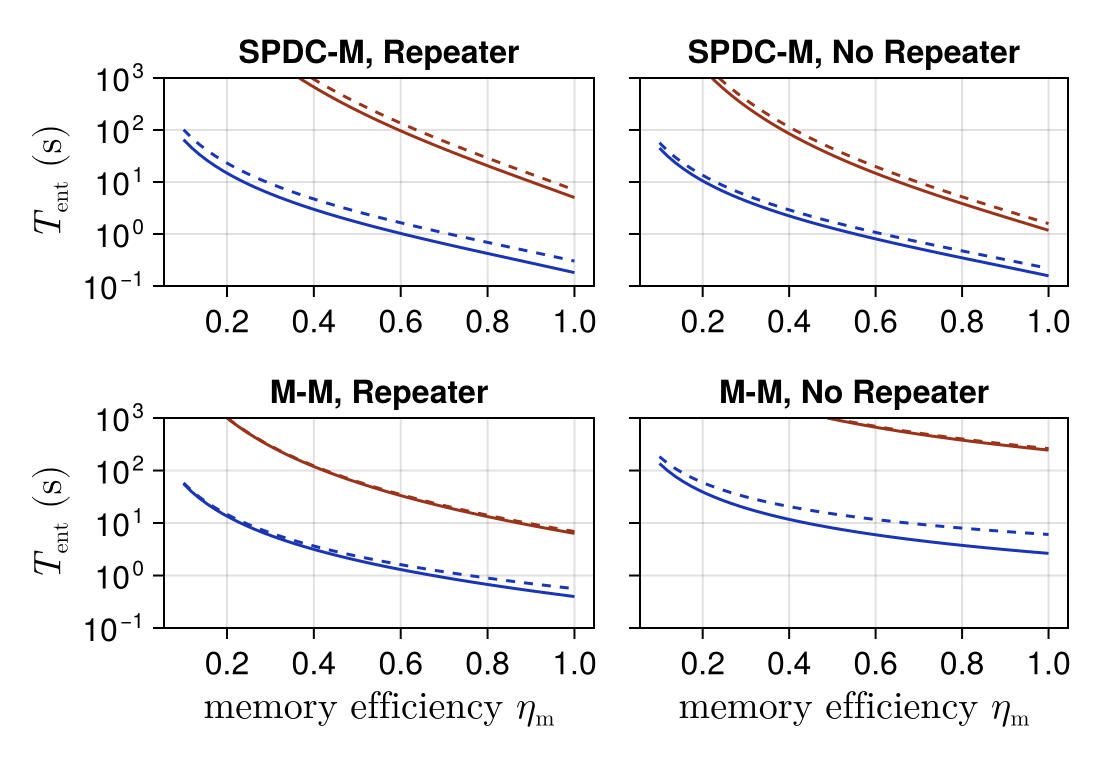

In [9]:
#Generate plot for Fig. 8(b) of main text.

fig8b = Figure(size = (550, 380))
C_red  = RGBf(0.6,0.2,0.1); C_blue = RGBf(0.1,0.21,0.7)
f_size, t_size, y_size, leg_size = 16, 16, 19, 14
ylm = (1e-1, 1e3);
colors = Dict(:SC => C_blue, :DC => C_red)
linestyles = Dict(:on => :dash, :off => :solid)
linestyle_labels = Dict(:on => "", :off  => "turn-off")
titles = [    "SPDC-M, Repeater"        "SPDC-M, No Repeater"; "M-M, Repeater"      "M-M, No Repeater"]
for (i, dataset) in enumerate((SPDC_M_results, M_M_results))
    for (j, repeater_label) in enumerate((:repeater, :no_repeater))
        ax = Axis(fig8b[i, j],ylabel = j ==  1 ?  L"T_{\mathrm{ent}} \ \mathrm{ (s)}" : "", yticklabelsvisible = (j == 1),xlabel = i == 2 ?  L"\mathrm{memory \ efficiency } \ \eta_{\mathrm{m}}" : "", yscale = log10, title = titles[i,j], xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size, xticklabelsize = f_size, yticklabelsize = f_size)
        ylims!(ax, ylm)
        for sc_label in (:SC, :DC)
            for turn_label in (:on, :off)
                T_ent = first.(dataset[(sc_label, turn_label, repeater_label)])
                lines!(ax, η_array, abs.(T_ent); color = colors[sc_label], linestyle = linestyles[turn_label], label = "$(sc_label), $(linestyle_labels[turn_label])")
            end
        end
    end
end

#save("Memory_Plot_PSetII.pdf", fig8b)
fig8b

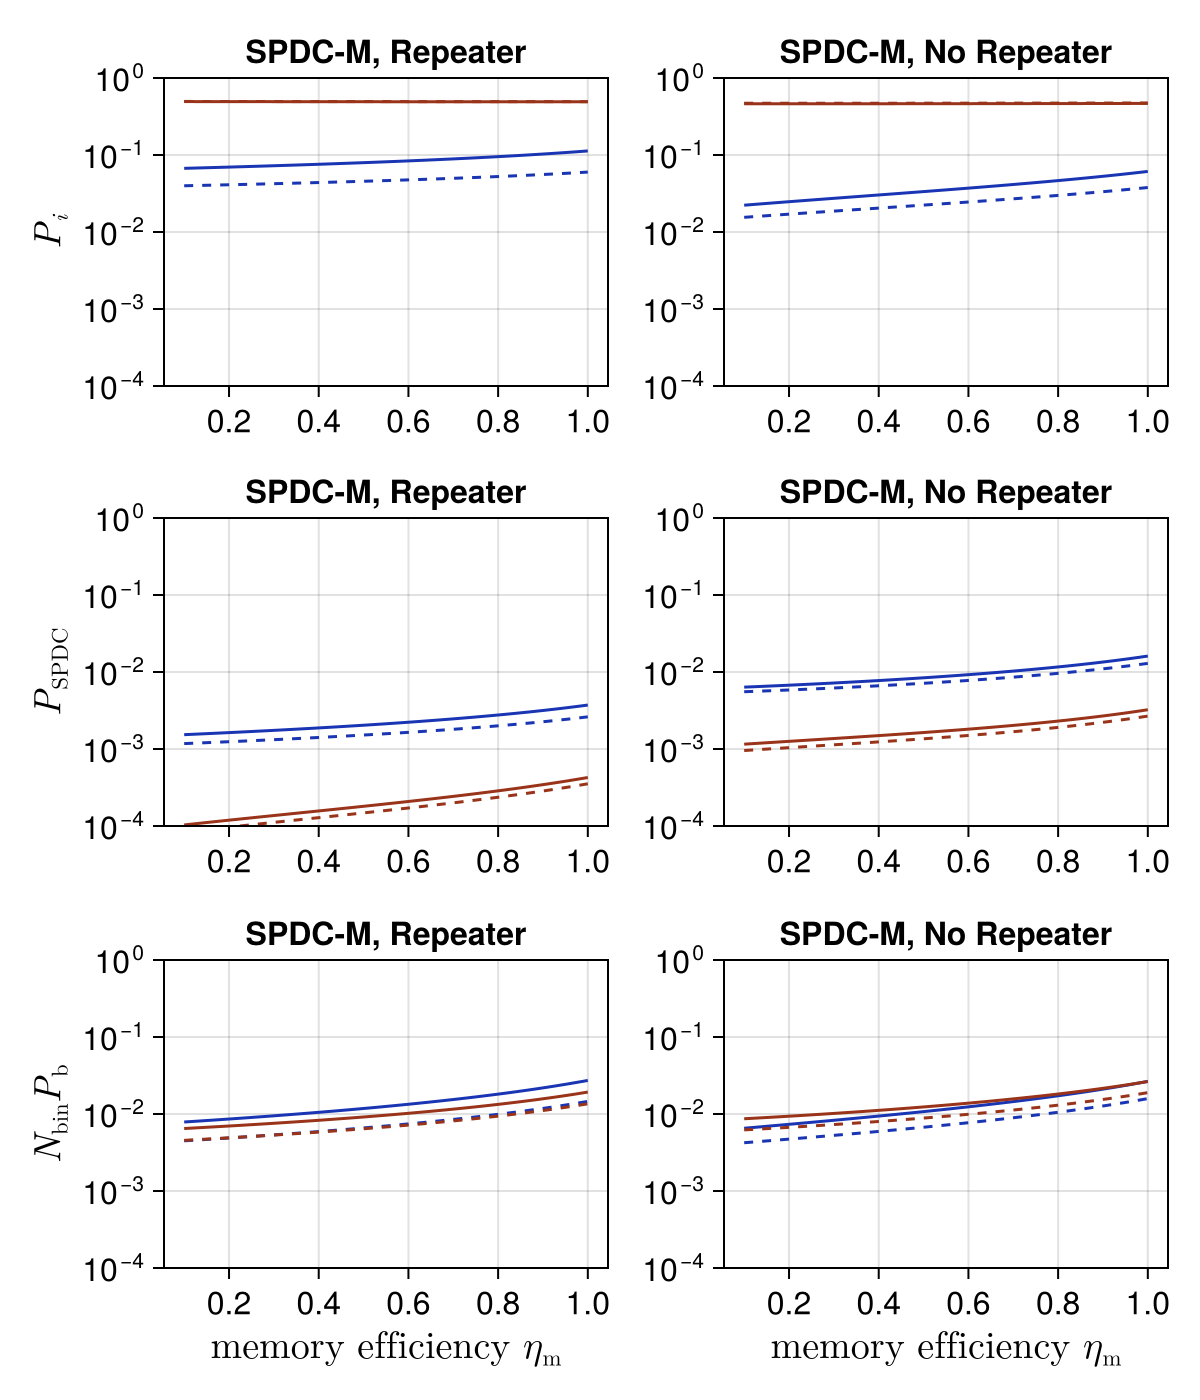

In [10]:
#Need to make plots of photon numbers for optimization, to make sure things are sensible.
figphot2 = Figure(size = (600, 700))
ylm = (1e-4,1); 
titles = [    "SPDC-M, Repeater"        "SPDC-M, No Repeater"]
for (j, repeater_label) in enumerate((:repeater, :no_repeater))
    ax = Axis(figphot2[1, j],ylabel = j ==  1 ?  L"P_i " : "", xlabel =  "", yscale = log10, title = titles[1,j], xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size, xticklabelsize = f_size, yticklabelsize = f_size)
    ylims!(ax, ylm)
    for sc_label in (:SC, :DC)
        for turn_label in (:on, :off)
            temp = getindex.(SPDC_M_results[(sc_label, turn_label, repeater_label)],5)
            lines!(ax, η_array,temp; color = colors[sc_label], linestyle = linestyles[turn_label], label = "$(sc_label), $(linestyle_labels[turn_label])")
        end
    end
    ax = Axis(figphot2[2, j],ylabel = j ==  1 ?  L"P_{\mathrm{SPDC}}" : "", xlabel = "", yscale = log10, title = titles[1,j], xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size, xticklabelsize = f_size, yticklabelsize = f_size)
    ylims!(ax, ylm)
    for sc_label in (:SC, :DC)
        for turn_label in (:on, :off)
            temp = getindex.(SPDC_M_results[(sc_label, turn_label, repeater_label)],6)
            lines!(ax, η_array, temp; color = colors[sc_label], linestyle = linestyles[turn_label], label = "$(sc_label), $(linestyle_labels[turn_label])")
        end
    end
    ax = Axis(figphot2[3, j],ylabel = j ==  1 ?  L"N_{\mathrm{bin}}P_{\mathrm{b}}" : "", xlabel =  L"\mathrm{memory \ efficiency } \ \eta_{\mathrm{m}}", yscale = log10, title = titles[1,j], xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size, xticklabelsize = f_size, yticklabelsize = f_size)
    ylims!(ax, ylm)
    for sc_label in (:SC, :DC)
        for turn_label in (:on, :off)
            temp = getindex.(SPDC_M_results[(sc_label, turn_label, repeater_label)],7)
            lines!(ax, η_array, N_bin*temp; color = colors[sc_label], linestyle = linestyles[turn_label], label = "$(sc_label), $(linestyle_labels[turn_label])")
        end
    end
end

figphot2